In [1]:
## JG comparison of proton transparency

In [2]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

def transparency(filename,bins_given):
    file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
    file3=uproot.open(filename)
    mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
    targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
    Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
    Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
    truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
    Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
    q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
    q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
    W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
    Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
    Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
    weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
    px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
    py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
    pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
    E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
    pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
    chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
    parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
    isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
    angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
    nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
    nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
    flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate
    
    incident_counter_w_med=file3['Events;1']['incident'].array()
    px_gibuu_w_med=file3['Events;1']['momX'].array()
    py_gibuu_w_med=file3['Events;1']['momY'].array()
    pz_gibuu_w_med=file3['Events;1']['momZ'].array()
    E_gibuu_w_med=file3['Events;1']['momE'].array()
    ID_gibuu_w_med=file3['Events;1']['ID'].array()
    charge_gibuu_w_med=file3['Events;1']['Charge'].array()
    history_gibuu_w_med=file3['Events;1']['history'].array()
    prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
    idx=np.arange(0,len(mode),1)
    mask_chase=ak.sum(chase, axis=1)>0
    idx=idx[mask_chase]
    print(idx,len(idx))  
    idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
    # idx=incident_counter_gibuu_wo_med1[idx]
    idx2=incident_counter_w_med[idx2]
    
    # _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
    _, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)
    
    bins_array=bins_given
    M_PROTON = 0.938   # GeV
    BINDING = 0.035    # GeV
    pdg_arr = pdg[idx1]
    chase_arr = chase[idx1]
    mode_arr=mode[idx1]
    E_arr = E[idx1]
    E_shift = E_arr - M_PROTON - BINDING
    E_primary=E_arr[:,3]- M_PROTON - BINDING
    px_arr=px[idx1]
    py_arr=py[idx1]
    pz_arr=pz[idx1]
    mode_arr=mode[idx1]
    def get_1_p_events_n(pdg,chase,Ekin):
        pdg_protons = pdg[((pdg == 2212) & (chase==1) & (Ekin>0.0))]
        pdg_hadrons = pdg[((pdg > 99) & (chase==1))]
        return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1) 
    mask_evt=get_1_p_events_n(pdg_arr,chase_arr,E_shift)  
    E_sel=E_shift[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
    px_sel=px_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
    py_sel=py_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
    pz_sel=pz_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
    
    E_evt = E_primary[mask_evt]
    px_evt= px_arr[:,3][mask_evt]
    py_evt= py_arr[:,3][mask_evt]
    pz_evt= pz_arr[:,3][mask_evt]
    def deviation(px_g,py_g,pz_g,init_px,init_py,init_pz):
       return np.nan_to_num(np.arccos((px_g * init_px + py_g * init_py + pz_g * init_pz) / (np.sqrt((px_g ** 2 + py_g ** 2 + pz_g ** 2)) * np.sqrt((init_px**2 + init_py**2 + init_pz**2)))),nan=0)     
    
    maskp=mode_arr==1
    mask_trans=ak.flatten(deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)<=5*np.pi/180)
    E_sel=ak.flatten(E_sel)
    hist1,bins1=np.histogram(E_sel[mask_trans],bins=bins_array, range=(0.0,1.5))
    hist2,bins2=np.histogram(E_primary[maskp], bins=bins_array,range=(0.,1.5))
    
    mask_trans4=ak.flatten(deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)<=10*np.pi/180)
    mask_trans5=ak.flatten(deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)<=15*np.pi/180)
    mask_trans6=ak.flatten(deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)<=20*np.pi/180)
    
    hist3,bins1=np.histogram(E_evt[mask_trans4],bins=bins_array, range=(0.0,1.5))
    hist4,bins1=np.histogram(E_evt[mask_trans5],bins=bins_array, range=(0.0,1.5))
    hist5,bins1=np.histogram(E_evt[mask_trans6],bins=bins_array, range=(0.0,1.5))
    
    
    
    binc=(bins1[1:]+bins1[:-1])/2
    
    
    E_arr3 = E_gibuu_w_med[idx2][:,2:]
    ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
    charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
    prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
    px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
    py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
    pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
    E_shift3 = E_arr3 - 0.938
    E_primary_gibuu=E_primary
    is_proton3 = ( (prod_id_arr3==1) &
        (ID_arr3 == 1) &
        (charge_arr3 == 1) &
        (E_shift3 > 0.0)  
        # (el_arrg>20*np.pi/180) & 
        # (el_arrg<40*np.pi/180) &
        # (ang_out_g>0*np.pi/180) & 
        # (ang_out_g<90*np.pi/180) 
    )
    
    is_neutron3 = ( (prod_id_arr3==1) &
        (ID_arr3 == 1) &
        (charge_arr3 == 0) &
        (E_shift3 > 0.0)  
        # (el_arrg>20*np.pi/180) & 
        # (el_arrg<40*np.pi/180) &
        # (ang_out_g>0*np.pi/180) & 
        # (ang_out_g<90*np.pi/180) 
    )
    # maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
    np_proton_event3=ak.sum(is_proton3, axis=1) == 1
    proton_mask_evt3 = is_proton3[np_proton_event3]
    neutron_mask_evt3 = is_neutron3[np_proton_event3]
    
    # E_evt_gibuu = E_primary_gibuu[np_proton_event3]
    E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
    pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
    has_gibuu_proton = ak.num(E_gibuu_sel) > 0
    has_gibuu_neutron = ak.num(E_shift3[np_proton_event3][neutron_mask_evt3]) > 0
    
    E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
    px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
    py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
    pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
    pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]
    
    sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)
    
    E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
    px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
    py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
    pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])
    
    E_evt3 = E_primary[np_proton_event3]
    px_evt3= px_arr[:,3][np_proton_event3]
    py_evt3= py_arr[:,3][np_proton_event3]
    pz_evt3= pz_arr[:,3][np_proton_event3]
    
    mask_trans_gibuu=deviation(px_evt3,py_evt3,pz_evt3,px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel)<=5*np.pi/180
    mask_trans_gibuu_neutron=has_gibuu_neutron==0
    
    mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])
    
    hist11,bins11=np.histogram(E_evt3[mask_trans_gibuu&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
    
    
    mask_trans_gibuu2=deviation(px_evt3,py_evt3,pz_evt3,px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel)<=10*np.pi/180
    mask_trans_gibuu3=deviation(px_evt3,py_evt3,pz_evt3,px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel)<=15*np.pi/180
    mask_trans_gibuu4=deviation(px_evt3,py_evt3,pz_evt3,px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel)<=20*np.pi/180
    
    hist22,bins11=np.histogram(E_evt3[mask_trans_gibuu&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
    hist33,bins11=np.histogram(E_evt3[mask_trans_gibuu3&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
    hist44,bins11=np.histogram(E_evt3[mask_trans_gibuu4&mask_trans_gibuu_neutron],bins=bins_array,range=(0.0,1.5))
    return hist1,hist2,hist3,hist4,hist4,hist11,hist22,hist33,hist44   


In [3]:
bins=np.arange(0,1.5,0.1)
hist1,hist2,hist3,hist4,hist5,hist11,hist22,hist33,hist44=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos5.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


/nfs/pic.es/user/p/pdasgupt/.local/lib/python3.14/site-packages/awkward/_nplikes/array_module.py:300: RuntimeWarning: invalid value encountered in arccos
  return impl(*broadcasted_args, **(kwargs or {}))


In [4]:
hist1c2o,hist2c2o,hist3c2o,hist4c2o,hist5c2o,hist11c2o,hist22c2o,hist33c2o,hist44c2o=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos5.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


<Array [0.689, 0.631, 0.63, 0.615, ..., 0.5, 0.504, 0.535] type='14 * float64'>

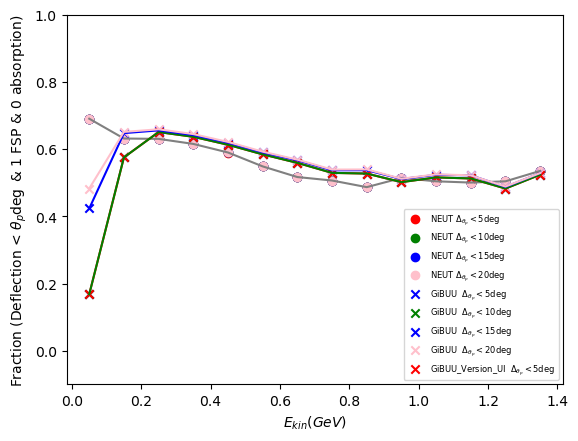

In [5]:
binc=(bins[1:]+bins[:-1])/2
plt.scatter(binc,hist1/hist2,color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")
plt.scatter(binc,hist3/hist2,color="green",marker="o", label=r"NEUT $\Delta_{\theta_p}<10\deg$")
plt.scatter(binc,hist4/hist2,color="blue",marker="o", label=r"NEUT $\Delta_{\theta_p}<15\deg$")
plt.scatter(binc,hist5/hist2,color="pink",marker="o", label=r"NEUT $\Delta_{\theta_p}<20\deg$")
plt.plot(binc,hist5/hist2,color="grey")

plt.ylim(-0.1,1.0)
plt.scatter(binc,hist11/hist2, color="blue",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<5\deg$")
plt.scatter(binc,hist22/hist2,color="green",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<10\deg$")
plt.scatter(binc,hist33/hist2,color="blue",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<15\deg$")
plt.scatter(binc,hist44/hist2,color="pink",marker="x", label=r"GiBUU  $\Delta_{\theta_p}<20\deg$")


plt.scatter(binc,hist11c2o/hist2c2o, color="red",marker="x", label=r"GiBUU_Version_UI  $\Delta_{\theta_p}<5\deg$")

plt.plot(binc,hist11/hist2, color="red")
plt.plot(binc,hist22/hist2,color="green")
plt.plot(binc,hist33/hist2,color="blue")
plt.plot(binc,hist44/hist2,color="pink")

plt.legend(fontsize=6)
plt.ylabel(r"Fraction (Deflection < $\theta_p \deg$ & 1 FSP & 0 absorption)")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]
hist1/hist2


In [6]:
hist1c1,hist2c1,hist3c1,hist4c1,hist5c1,hist11c1,hist22c1,hist33c1,hist44c1=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos1.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


In [7]:
hist1c3,hist2c3,hist3c3,hist4c3,hist5c3,hist11c3,hist22c3,hist33c3,hist44c3=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos3.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


In [8]:
hist1c0,hist2c0,hist3c0,hist4c0,hist5c0,hist11c0,hist22c0,hist33c0,hist44c0=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos0.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


In [9]:
hist1c2,hist2c2,hist3c2,hist4c2,hist5c2,hist11c2,hist22c2,hist33c2,hist44c2=transparency("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos2.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000


Text(0.5, 0, '$E_{kin}(GeV)$')

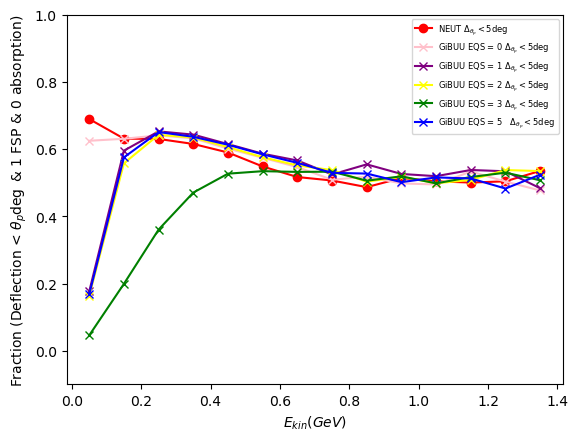

In [10]:
binc=(bins[1:]+bins[:-1])/2
plt.plot(binc,hist1/hist2,color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")


plt.ylim(-0.1,1.0)
plt.plot(binc,hist11c0/hist2c0,color="pink",marker="x", label=r"GiBUU EQS = 0 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c1/hist2c1,color="purple",marker="x", label=r"GiBUU EQS = 1 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c2/hist2c2,color="yellow",marker="x", label=r"GiBUU EQS = 2 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c3/hist2c3,color="green",marker="x", label=r"GiBUU EQS = 3 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11/hist2, color="blue",marker="x", label=r"GiBUU EQS = 5   $\Delta_{\theta_p}<5\deg$")

plt.legend(fontsize=6)
plt.ylabel(r"Fraction (Deflection < $\theta_p \deg$ & 1 FSP & 0 absorption)")
plt.xlabel(r"$E_{kin}(GeV)$")
# # E_sel3 = E_evt3[mask_evt3]

In [11]:
def transparency_mom(filename,bins_given):
    file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
    file3=uproot.open(filename)
    mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
    targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
    Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
    Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
    truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
    Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
    q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
    q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
    W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
    Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
    Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
    weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
    px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
    py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
    pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
    E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
    pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
    chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
    parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
    isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
    angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
    nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
    nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
    flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate
    
    incident_counter_w_med=file3['Events;1']['incident'].array()
    px_gibuu_w_med=file3['Events;1']['momX'].array()
    py_gibuu_w_med=file3['Events;1']['momY'].array()
    pz_gibuu_w_med=file3['Events;1']['momZ'].array()
    E_gibuu_w_med=file3['Events;1']['momE'].array()
    ID_gibuu_w_med=file3['Events;1']['ID'].array()
    charge_gibuu_w_med=file3['Events;1']['Charge'].array()
    history_gibuu_w_med=file3['Events;1']['history'].array()
    prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
    idx=np.arange(0,len(mode),1)
    mask_chase=ak.sum(chase, axis=1)>0
    idx=idx[mask_chase]
    print(idx,len(idx))  
    idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
    # idx=incident_counter_gibuu_wo_med1[idx]
    idx2=incident_counter_w_med[idx2]
    
    # _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
    _, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)
    pdgf=ak.flatten(pdg[idx1])
    chasef=ak.flatten(chase[idx1])
    Ef=ak.flatten(E[idx1])
    Pxf=ak.flatten(px[idx1])
    Pyf=ak.flatten(py[idx1])
    Pzf=ak.flatten(pz[idx1])
    Ptf=np.sqrt(Pxf**2+Pyf**2)
    Costhetaf=Pzf/np.sqrt(Pxf**2+Pyf**2+Pzf**2)
    modef=ak.flatten(mode[idx1]*ak.ones_like(pdg[idx1]))
    enf=ak.flatten(truenuE[idx1]*ak.ones_like(pdg[idx1]))
    # ################################
    pdgf_gibuu_w_med=ak.flatten(ID_gibuu_w_med[idx2][:,2:])
    chargef_gibuu_w_med=ak.flatten(charge_gibuu_w_med[idx2][:,2:])
    historyf_gibuu_w_med=ak.flatten(history_gibuu_w_med[idx2][:,2:])
    pxf_gibuu_w_med=ak.flatten(px_gibuu_w_med[idx2][:,2:])
    pyf_gibuu_w_med=ak.flatten(py_gibuu_w_med[idx2][:,2:])
    pzf_gibuu_w_med=ak.flatten(pz_gibuu_w_med[idx2][:,2:])
    ptf_gibuu_w_med=np.sqrt(pxf_gibuu_w_med**2+pyf_gibuu_w_med**2)
    modef_gibuu=ak.flatten(mode[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
    enf_gibuu=ak.flatten(truenuE[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
    Ef_gibuu_w_med=ak.flatten(E_gibuu_w_med[idx2][:,2:])
    costheta_w_med=pzf_gibuu_w_med/np.sqrt(pxf_gibuu_w_med*pxf_gibuu_w_med+pyf_gibuu_w_med*pyf_gibuu_w_med+pzf_gibuu_w_med*pzf_gibuu_w_med)
    costheta_w_med[costheta_w_med<=np.cos(np.pi)]
    
    bins_array=bins_given
    M_PROTON = 0.938   # GeV
    BINDING = 0.035    # GeV
    pdg_arr = pdg[idx1]
    chase_arr = chase[idx1]
    mode_arr=mode[idx1]
    E_arr = E[idx1]
    E_shift = E_arr - M_PROTON - BINDING
    E_primary=E_arr[:,3]- M_PROTON - BINDING
    el_arr=angle[idx1][:,2]
    px_arr=px[idx1]
    py_arr=py[idx1]
    pz_arr=pz[idx1]
    def get_1_p_events(pdg,chase,en):
        pdg_protons = pdg[((pdg == 2212) & (chase==1) & (en>0.0))]
        pdg_hadrons = pdg[((pdg > 99)& (chase==1))]
        return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1)  
    mask_evt=get_1_p_events(pdg_arr,chase_arr,E_shift)  
    E_sel=E_shift[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
    px_sel=px_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
    py_sel=py_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
    pz_sel=pz_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]

    E_evt = E_primary[mask_evt]
    px_evt= px_arr[mask_evt][:,3]
    py_evt= py_arr[mask_evt][:,3]
    pz_evt= pz_arr[mask_evt][:,3]
    
    def deviation(px_g,py_g,pz_g,init_px,init_py,init_pz):
       return np.nan_to_num(np.arccos((px_g * init_px + py_g * init_py + pz_g * init_pz) / (np.sqrt((px_g ** 2 + py_g ** 2 + pz_g ** 2)) * np.sqrt((init_px**2 + init_py**2 + init_pz**2)))),nan=0)     
    
    mask_trans=ak.flatten(deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)<=5*np.pi/180)
    mom_trans=np.sqrt(px_evt*px_evt+py_evt*py_evt+pz_evt*pz_evt)
    maskp=mode_arr==1

    hist1,bins1=np.histogram(mom_trans,bins=bins_array, range=(0.2,1.5))
    hist2,bins2=np.histogram(np.sqrt(px_arr[maskp][:,3]*px_arr[maskp][:,3]+py_arr[maskp][:,3]*py_arr[maskp][:,3]+pz_arr[maskp][:,3]*pz_arr[maskp][:,3]), bins=bins_array,range=(0.,1.5))
    
    binc=(bins1[1:]+bins1[:-1])/2
    
    
    E_arr3 = E_gibuu_w_med[idx2][:,2:]
    ID_arr3 = ID_gibuu_w_med[idx2][:,2:]
    charge_arr3 = charge_gibuu_w_med[idx2][:,2:]
    prod_id_arr3=prodid_gibuu_w_med[idx2][:,2:]
    px_gibuu_arr=px_gibuu_w_med[idx2][:,2:]
    py_gibuu_arr=py_gibuu_w_med[idx2][:,2:]
    pz_gibuu_arr=pz_gibuu_w_med[idx2][:,2:]
    # ang_out_g=np.arctan2(np.sqrt(px_gibuu_arr*px_gibuu_arr+py_gibuu_arr*py_gibuu_arr),pz_gibuu_arr)
    E_shift3 = E_arr3 - 0.938
    E_primary_gibuu=E_primary
    el_arrg=el_arr
    is_proton3 = ( (prod_id_arr3==1) &
        (ID_arr3 == 1) &
        (charge_arr3 == 1) &
        (E_shift3 > 0.0)  
        # (el_arrg>20*np.pi/180) & 
        # (el_arrg<40*np.pi/180) &
        # (ang_out_g>0*np.pi/180) & 
        # (ang_out_g<90*np.pi/180) 
    )
    # maskelg=(el_arrg>20*np.pi/180) & (el_arrg<40*np.pi/180)
    np_proton_event3=ak.sum(is_proton3, axis=1) == 1
    proton_mask_evt3 = is_proton3[np_proton_event3]
    
    # E_evt_gibuu = E_primary_gibuu[np_proton_event3]
    E_gibuu_sel = E_shift3[np_proton_event3][proton_mask_evt3]
    pxout_gibuu_sel=px_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pyout_gibuu_sel=py_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pzout_gibuu_sel=pz_gibuu_arr[np_proton_event3][proton_mask_evt3]
    pdg_gibuu_sel=ID_arr3[np_proton_event3][proton_mask_evt3]
    has_gibuu_proton = ak.num(E_gibuu_sel,axis=1) > 0
    
    E_gibuu_sel = E_gibuu_sel[has_gibuu_proton]
    px_gibuu_sel = pxout_gibuu_sel[has_gibuu_proton]
    py_gibuu_sel = pyout_gibuu_sel[has_gibuu_proton]
    pz_gibuu_sel = pzout_gibuu_sel[has_gibuu_proton]
    pdg_gibuu_sel=pdg_gibuu_sel[has_gibuu_proton]
    
    sorted_gibuu_idx=ak.argsort(E_gibuu_sel,axis=1,ascending=False)
    
    E_gibuu_sel=ak.firsts(E_gibuu_sel[sorted_gibuu_idx])
    px_gibuu_sel=ak.firsts(px_gibuu_sel[sorted_gibuu_idx])
    py_gibuu_sel=ak.firsts(py_gibuu_sel[sorted_gibuu_idx])
    pz_gibuu_sel=ak.firsts(pz_gibuu_sel[sorted_gibuu_idx])
    
    E_evt3 = E_primary[np_proton_event3]
    px_evt3= px_arr[:,3][np_proton_event3]
    py_evt3= py_arr[:,3][np_proton_event3]
    pz_evt3= pz_arr[:,3][np_proton_event3]
    
    mask_trans_gibuu=deviation(px_evt3,py_evt3,pz_evt3,px_gibuu_sel,py_gibuu_sel,pz_gibuu_sel)<=5*np.pi/180
    mom_trans_gibuu=np.sqrt(px_evt3[mask_trans_gibuu]*px_evt3[mask_trans_gibuu]+py_evt3[mask_trans_gibuu]*py_evt3[mask_trans_gibuu]+pz_evt3[mask_trans_gibuu]*pz_evt3[mask_trans_gibuu])
    
    hist11,bins11=np.histogram(mom_trans_gibuu,bins=bins_array,range=(0.,1.5))
    return hist1,hist2, hist11


In [12]:
bins=np.arange(0,5,0.25)
hist1c0p,hist2c0p,hist11c0p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos0.root",bins)
hist1c1p,hist2c1p,hist11c1p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos1.root",bins)
hist1c3p,hist2c2p,hist11c2p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos2.root",bins)
hist1c3p,hist2c3p,hist11c3p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos3.root",bins)
hist1c5p,hist2c5p,hist11c5p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos5.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000


Text(0.5, 0, '$p(GeV/c)$')

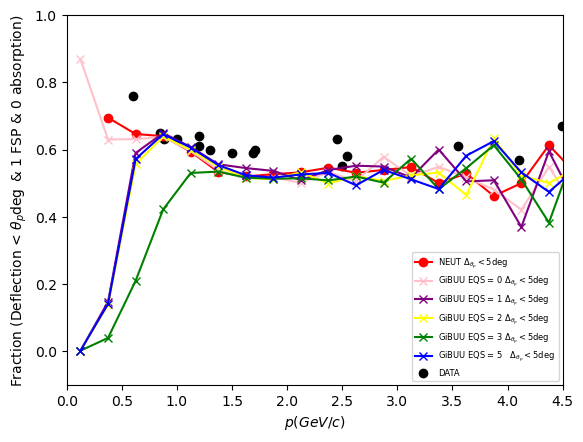

In [13]:
binc=(bins[1:]+bins[:-1])/2
X=np.array([ (0.60,0.76),
    (0.85, 0.65),
    (0.88,0.63),
    (1.00, 0.63),
    (1.20,0.64),
    (1.20,0.61),
    (1.30,0.60),
    (1.50,0.59),
    (1.69,0.59),
    (1.71,0.60),
    (2.45,0.63),
    (2.50,0.55),
    (2.54,0.58),
    (3.55,0.61),
    (4.10,0.57),
    (4.49,0.67),
    (5.15,0.58)])
plt.plot(binc[1:],hist1c0p[1:]/hist2c0p[1:],color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")
plt.ylim(-0.1,1.0)
plt.plot(binc,hist11c0p/hist2c0p,color="pink",marker="x", label=r"GiBUU EQS = 0 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c1p/hist2c1p,color="purple",marker="x", label=r"GiBUU EQS = 1 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c2p/hist2c2p,color="yellow",marker="x", label=r"GiBUU EQS = 2 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c3p/hist2c3p,color="green",marker="x", label=r"GiBUU EQS = 3 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c5p/hist2c5p, color="blue",marker="x", label=r"GiBUU EQS = 5   $\Delta_{\theta_p}<5\deg$")
plt.scatter(X[:,0],X[:,1],color="black",marker="o",label="DATA")
plt.legend(fontsize=6)
plt.xlim(0,4.5)
plt.ylabel(r"Fraction (Deflection < $\theta_p \deg$ & 1 FSP & 0 absorption)")
plt.xlabel(r"$p(GeV/c)$")

In [14]:
file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos0.root")
mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate

incident_counter_w_med=file3['Events;1']['incident'].array()
px_gibuu_w_med=file3['Events;1']['momX'].array()
py_gibuu_w_med=file3['Events;1']['momY'].array()
pz_gibuu_w_med=file3['Events;1']['momZ'].array()
E_gibuu_w_med=file3['Events;1']['momE'].array()
ID_gibuu_w_med=file3['Events;1']['ID'].array()
charge_gibuu_w_med=file3['Events;1']['Charge'].array()
history_gibuu_w_med=file3['Events;1']['history'].array()
prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
idx=np.arange(0,len(mode),1)
mask_chase=ak.sum(chase, axis=1)>0
idx=idx[mask_chase]
print(idx,len(idx))  
idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
# idx=incident_counter_gibuu_wo_med1[idx]
idx2=incident_counter_w_med[idx2]

# _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
_, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)
pdgf=ak.flatten(pdg[idx1])
chasef=ak.flatten(chase[idx1])
Ef=ak.flatten(E[idx1])
Pxf=ak.flatten(px[idx1])
Pyf=ak.flatten(py[idx1])
Pzf=ak.flatten(pz[idx1])
Ptf=np.sqrt(Pxf**2+Pyf**2)
Costhetaf=Pzf/np.sqrt(Pxf**2+Pyf**2+Pzf**2)
modef=ak.flatten(mode[idx1]*ak.ones_like(pdg[idx1]))
enf=ak.flatten(truenuE[idx1]*ak.ones_like(pdg[idx1]))
# ################################
pdgf_gibuu_w_med=ak.flatten(ID_gibuu_w_med[idx2][:,2:])
chargef_gibuu_w_med=ak.flatten(charge_gibuu_w_med[idx2][:,2:])
historyf_gibuu_w_med=ak.flatten(history_gibuu_w_med[idx2][:,2:])
pxf_gibuu_w_med=ak.flatten(px_gibuu_w_med[idx2][:,2:])
pyf_gibuu_w_med=ak.flatten(py_gibuu_w_med[idx2][:,2:])
pzf_gibuu_w_med=ak.flatten(pz_gibuu_w_med[idx2][:,2:])
ptf_gibuu_w_med=np.sqrt(pxf_gibuu_w_med**2+pyf_gibuu_w_med**2)
modef_gibuu=ak.flatten(mode[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
enf_gibuu=ak.flatten(truenuE[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
Ef_gibuu_w_med=ak.flatten(E_gibuu_w_med[idx2][:,2:])
costheta_w_med=pzf_gibuu_w_med/np.sqrt(pxf_gibuu_w_med*pxf_gibuu_w_med+pyf_gibuu_w_med*pyf_gibuu_w_med+pzf_gibuu_w_med*pzf_gibuu_w_med)
costheta_w_med[costheta_w_med<=np.cos(np.pi)]

# bins_array=bins_given
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
el_arr=angle[idx1][:,2]
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
# is_good_proton = ( (mode_arr==1) &
#     (pdg_arr == 2212) &
#     (chase_arr == 1) &
#     (E_shift > 0.0) 
#     # (el_arr>20*np.pi/180) & 
#     # (el_arr<40*np.pi/180) 
# )
# is_bad_proton = ( (mode_arr==1) &
#     (pdg_arr == 2212) &
#     (chase_arr == 0)

# )
# np_proton_event=ak.sum(is_good_proton, axis=1) > 0
def get_1_p_events(pdg,chase,en):
    pdg_protons = pdg[((pdg == 2212) & (chase==1) & (en>0.))]
    pdg_hadrons = pdg[((pdg > 99)&(chase==1))]
    return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)<3)  
mask_evt=get_1_p_events(pdg_arr,chase_arr,E_shift)  
E_sel=E_shift[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
px_sel=px_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
py_sel=py_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]
pz_sel=pz_arr[mask_evt][(mode[mask_evt]==1)&(pdg_arr[mask_evt]==2212)]

E_evt = E_primary[mask_evt]
px_evt= px_arr[mask_evt][:,3]
py_evt= py_arr[mask_evt][:,3]
pz_evt= pz_arr[mask_evt][:,3]

[     0      1      2 ... 799997 799998 799999] 800000


In [15]:
px_evt

<Array [-0.618, -0.277, 0.17, ..., -0.162, -0.279] type='490234 * float64'>

In [16]:
px_arr[mask_evt]

<Array [[0, 0.116, 0.733, -0.618], ..., [0, ...]] type='490234 * var * float64'>

In [17]:
pdg_to_mass = {
    13: 0.10566,
    14: 0,

    22: 0,

    130: 0.49761,
    310: 0.49761,

    111: 0.13498,
    211: 0.13957,

    221: 0.54785,
    223: 0.78265,

    311: 0.49761,
    321: 0.49368,

    2112: 0.93957,
    2212: 0.93827,

    1114: 1.232,
    2114: 1.232,
    2214: 1.232,
    2224: 1.232,

    3122: 1.1157,

    3112: 1.1974,
    3212: 1.1926,
    3222: 1.1894,

    3312: 1.3217,
    3322: 1.3149,
}
ID_to_pdg = {
    # Nucleons resonance
    (1,+0): 2112,
    (1,+1): 2212,

    (2,-1): 1114,
    (2,+0): 2114,
    (2,+1): 2214,
    (2,2): 2224,
    
    (3,+0): 202112,
    (3,+1): 202212,

    (4,+0): 102112,
    (4,+1): 102212,

    (5,+0): 122112,
    (5,+1): 122212,

    (7,+0): 102114,
    (7,+1): 102214,

    (8,+0): 112114,
    (8,+1): 112214,

    (10,+0): 102116,
    (10,+1): 102216,

    (12,+0): 212112,
    (12,+1): 212212,

    (14,+0): 212114,
    (14,+1): 212214,

    (16,+0): 202116,
    (16,+1): 202216,

    (19,-1): 111112,
    (19,+0): 112112,
    (19,+1): 112212,
    (19,+2): 112222,

    (21,-1): 121114,
    (21,+0): 122114,
    (21,+1): 122214,
    (21,+2): 122224,

    (26,-1): 221112,
    (26,+0): 222112,
    (26,+1): 222212,
    (26,+2): 222222,

    (27,-1): 201114,
    (27,+0): 202114,
    (27,+1): 202214,
    (27,+2): 202224,

    (28,-1): 221114,
    (28,+0): 222114,
    (28,+1): 222214,
    (28,+2): 222224,

    (30,-1): 211116,
    (30,+0): 212116,
    (30,+1): 212216,
    (30,+2): 212226,
    
    (31,-1): 201118,
    (31,+0): 202118,
    (31,+1): 202218,
    (31,+2): 202228,

    # Baryons with strangeness s=-1
    (32,+0): 3122,

    (33,-1): 3112,
    (33,+0): 3212,
    (33,+1): 3222,

    (34,-1): 3114,
    (34,+0): 3214,
    (34,+1): 3224,

    (35,+0): 102132,
    (36,+0): 102134,
    (37,+0): 203122,
    (38,+0): 103122,
    (39,+0): 103124,
    (40,+0): 213122,
    (41,+0): 203126,
    (42,+0): 103126,

    (43,-1): 103114,
    (43,+0): 103214,
    (43,+1): 103224,

    (44,-1): 103116,
    (44,+0): 103216,
    (44,+1): 103226,

    (45,-1): 203118,
    (45,+0): 203218,
    (45,+1): 203228,

    (46,+0): 123122,
    (47,+0): 213124,

    (50,-1): 203112,
    (50,+0): 203212,
    (50,+1): 203222,

    (51,-1): 113112,
    (51,+0): 113212,
    (51,+1): 113222,

    (52,-1): 203116,
    (52,+0): 203216,
    (52,+1): 203226,

    # Baryons with strangeness s=-2
    (53,-1): 3312,
    (53,+0): 3322,

    (54,-1): 3314,
    (54,+0): 3324,

    # Baryons with strangeness s=-3
    (55,-1): 3334,

    # Baryons with charm c=+1
    (56,+1): 4122,

    (57,+0): 4112,
    (57,+1): 4212,
    (57,+2): 4222,

    (58,+0): 4114,
    (58,+1): 4214,
    (58,+2): 4224,

    (59,+0): 4132,
    (59,+1): 4232,

    (60,+0): 4314,
    (60,+1): 4324,

    (61,+0): 4332,

    # Mesons
    (101,-1): -211,
    (101,+0): +111,
    (101,+1): +211,

    (102,+0): 221,

    (103,-1): -213,
    (103,+0): +113,
    (103,+1): +213,

    (104, +0): 9000221,
    (105, +0): 223,
    (106, +0): 331,
    (107, +0): 333,
    (108, +0): 441,
    (109, +0): 443,

    (110,+0): 311,
    (110,+1): 321,
    
    (111,-1): -321,
    (111,+0): -311,

    (112,+0): 313,
    (112,+1): 323,

    (113,-1): -323,
    (113,+0): -313,

    (114,+0): 411,
    (114,+1): 421,

    (115,-1): -421,
    (115,+0): -411,

    (116,+0): 413,
    (116,+1): 423,

    (117,-1): -423,
    (117,+0): -413,
    
    (118,+1): 431,
    (119,-1): -431,
    (120,+1): 433,
    (121,-1): -433,
    (122,+0): 225,

    # Leptons
    (901,-1): 11,
    (902,-1): 13,
    (903,-1): 15,
    
    (911,+0): 12,
    (912,+0): 14,
    (913,+0): 16,

    # Gauge bosons
    (997,-1): -24,
    (997,+1): 24,
    (998,+0): 23,
    (999,+0): 22,

    # Antiparticles
    (-1,+0): -2112,
    (-1,-1): -2212,
}

def mass_from_pdg(PDG):
    """
    Determine masses of particles from PDG ID
    
    **Arguments**
    - **PDG** An awkward array of PDG ID

    **Returns**

    - awkward array of same dimension containing the masses of the particles
    """
    pdg_flatten = np.abs(ak.flatten(PDG))
    
    res = ak.to_numpy(ak.zeros_like(ak.values_astype(pdg_flatten, 'float64')))
    for (i, val) in pdg_to_mass.items():
        mask = (pdg_flatten == i)
        res[mask] = val

    remaining = np.unique(pdg_flatten[(res==0) & ~((pdg_flatten==12)|(pdg_flatten==14)|(pdg_flatten==16)|(pdg_flatten==22))])
    if len(remaining) > 0:
        print(f"Unassigned masses : {remaining}")
    return ak.unflatten(res, ak.num(PDG))
# GiBUU particles that have no PDG equivalent
no_PDG = [6, 9, 11, 13, 15, 17, 18, 20, 22, 23, 24, 25, 29, 48, 49]

def pdg_from_id(ID, Charge):
    """
    Determine PDG id from GiBUU ID and charge of particles
    
    **Arguments**
    - **ID** An awkward array of GiBUU particle ID

    - **Charge** An awkward array of particle charges of same shape as ID

    **Returns**

    - awkward array of same dimension containing PDG id of particles
    """
    ID_flatten = ak.flatten(ID)
    Charge_flatten = ak.flatten(Charge)
    
    res= ak.to_numpy(ak.zeros_like(Charge_flatten))
    for ((i, charge), val) in ID_to_pdg.items():
        mask = (ID_flatten == i) & (Charge_flatten == charge)
        res[mask] = val
    for i in no_PDG:
        errors = Charge_flatten[ID_flatten==i]
        if len(errors) > 0:
            for c in errors:
                print(f"Particle with ID {i} and charge {c} has no PDG")
    mask = res==0
    masked_id = ID_flatten[mask]
    masked_charge = Charge_flatten[mask]
    remaining = np.column_stack((masked_id, masked_charge))
    uniques = np.unique(remaining, axis=0)
    for (i,c) in uniques:
        print(f"! No pdg found for particle with ID {i} and charge {c}")
    return ak.unflatten(res, ak.num(ID))


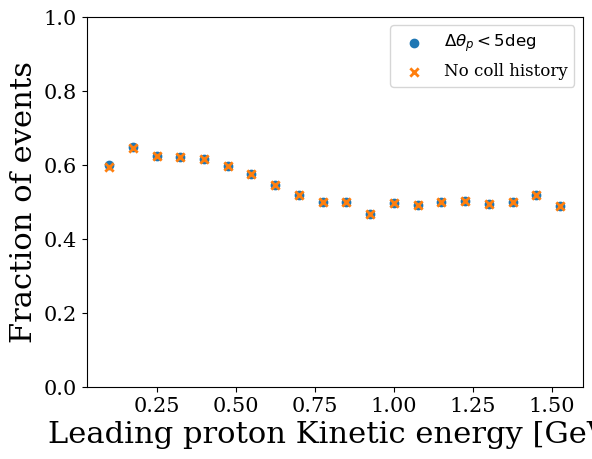

In [18]:
from matplotlib import rc
import matplotlib.font_manager
bins_given=np.arange(0,1.5,0.1)

file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate

costheta = np.cos(angle)
 
mass = mass_from_pdg(pdg)

Ekin = E - mass
rc('font', family='serif')
rc('text', usetex=False)
rc('font', size=22) 
rc('xtick', labelsize=15) 
rc('ytick', labelsize=15) 
rc('legend', fontsize=15)

def get_1_p_events_n(pdg,chase,Ekin):
    pdg_protons = pdg[((pdg == 2212) & (chase==1) & (Ekin>0.035))]
    pdg_hadrons = pdg[((pdg > 99) & (chase==1))]
    return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1)
mask_n = get_1_p_events_n(pdg, chase, Ekin)
protons = (pdg[mask_n]==2212) & (chase[mask_n]==1) & (Ekin[mask_n] > 0.035)
protons_count = np.sum(protons, axis=1)

E_mask_ned = E[mask_n]

E_p_max = ak.max(E_mask_ned[protons], axis=1)
p_index = (E_mask_ned==E_p_max)
deviation = np.nan_to_num(np.arccos((px[mask_n][p_index][:,0] * px[mask_n][:,3] + py[mask_n][p_index][:,0] * py[mask_n][:,3] + pz[mask_n][p_index][:,0] * pz[mask_n][:,3]) / (np.sqrt(
    (px[mask_n][p_index][:,0] ** 2 + py[mask_n][p_index][:,0] ** 2 + pz[mask_n][p_index][:,0] ** 2)) * np.sqrt(
    (px[mask_n][:,3]**2 + py[mask_n][:,3]**2 + pz[mask_n][:,3]**2)))), nan=0)
N = 20
bins = np.linspace(0,1.5,N+1)
p = bins[1] - bins[0]
bins_mid = np.arange(0.1,N*p+0.1,p)
case_1 = Ekin[mask_n][p_index][:,0][deviation < 5*180/np.pi]

case_1_hist_n = np.histogram(case_1, bins=bins)[0]
case_2 = Ekin[mask_n][p_index][:,0][ak.num(pdg[mask_n])==4]

case_2_hist_n = np.histogram(case_2, bins=bins)[0]
denominator = E[:,3] - 0.93827

denominator_hist_n = np.histogram(denominator, bins=bins)[0]
# plt.scatter(bins_mid, case_1_hist / denominator_hist, label='Case 1 GiBUU')
# plt.scatter(bins_mid, case_2_hist / denominator_hist, label='Case 2 GiBUU', marker='x', linewidth=2)
plt.scatter(bins_mid, case_1_hist_n / denominator_hist_n, label=r"$\Delta \theta_p <5\deg$")
plt.scatter(bins_mid, case_2_hist_n / denominator_hist_n, label="No coll history", marker='x', linewidth=2)

plt.ylabel('Fraction of events')
plt.xlabel('Leading proton Kinetic energy [GeV]')
plt.ylim(0,1)
plt.legend(fontsize=12)
plt.show()

In [19]:
len(E[mask_evt])

490234

In [20]:
len(E_sel)

490234

In [21]:
ak.sum(chase_arr,axis=1)

<Array [2, 2, 2, 3, 5, 2, 2, 2, ..., 2, 2, 3, 5, 2, 2, 2] type='656781 * int64'>

In [22]:
E_sel+0.938+0.035

<Array [[1.57], [0.994], ..., [1.08], [1.27]] type='490234 * var * float64'>

In [23]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
file3=uproot.open("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos5.root")
mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate

incident_counter_w_med=file3['Events;1']['incident'].array()
px_gibuu_w_med=file3['Events;1']['momX'].array()
py_gibuu_w_med=file3['Events;1']['momY'].array()
pz_gibuu_w_med=file3['Events;1']['momZ'].array()
E_gibuu_w_med=file3['Events;1']['momE'].array()
ID_gibuu_w_med=file3['Events;1']['ID'].array()
charge_gibuu_w_med=file3['Events;1']['Charge'].array()
history_gibuu_w_med=file3['Events;1']['history'].array()
prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
idx=np.arange(0,len(mode),1)
mask_chase=ak.sum(chase, axis=1)>0
idx=idx[mask_chase]
print(idx,len(idx))  
idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
# idx=incident_counter_gibuu_wo_med1[idx]
idx2=incident_counter_w_med[idx2]

# _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
_, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)

bins_array=bins_given
M_PROTON = 0.938   # GeV
BINDING = 0.035    # GeV
pdg_arr = pdg[idx1]
chase_arr = chase[idx1]
mode_arr=mode[idx1]
E_arr = E[idx1]
E_shift = E_arr - M_PROTON - BINDING
E_primary=E_arr[:,3]- M_PROTON - BINDING
px_arr=px[idx1]
py_arr=py[idx1]
pz_arr=pz[idx1]
mode_arr=mode[idx1]
def get_1_p_events_n(pdg,chase,Ekin):
    pdg_protons = pdg[((pdg == 2212) & (chase==1) & (Ekin>0.0))]
    pdg_hadrons = pdg[((pdg > 99) & (chase==1))]
    return (ak.num(pdg_protons)==1) & (ak.num(pdg_hadrons)==1) 
mask_evt=get_1_p_events_n(pdg_arr,chase_arr,E_shift)  
E_sel=E_shift[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
px_sel=px_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
py_sel=py_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]
pz_sel=pz_arr[mask_evt][((pdg_arr[mask_evt]==2212)&(chase_arr[mask_evt]==1))]

E_evt = E_primary[mask_evt]
px_evt= px_arr[:,3][mask_evt]
py_evt= py_arr[:,3][mask_evt]
pz_evt= pz_arr[:,3][mask_evt]
def deviation(px_g,py_g,pz_g,init_px,init_py,init_pz):
   return np.arccos((px_g * init_px + py_g * init_py + pz_g * init_pz) / (np.sqrt((px_g ** 2 + py_g ** 2 + pz_g ** 2)) * np.sqrt((init_px**2 + init_py**2 + init_pz**2))))     


[     0      1      2 ... 799997 799998 799999] 800000


In [24]:
deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)

<Array [[0], [nan], ..., [2.11e-08], [0]] type='467048 * var * float64'>

In [25]:
def cos_dev(px_g,py_g,pz_g,init_px,init_py,init_pz):
    return ((px_g * init_px + py_g * init_py + pz_g * init_pz) / (np.sqrt((px_g ** 2 + py_g ** 2 + pz_g ** 2)) * np.sqrt((init_px**2 + init_py**2 + init_pz**2))))

In [26]:
A=cos_dev(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)
B=deviation(px_evt,py_evt,pz_evt,px_sel,py_sel,pz_sel)

In [27]:
A1=A[np.isnan(B)]

In [28]:
np.unique(ak.flatten(A1))

<Array [1] type='1 * float64'>

In [29]:
A

<Array [[1], [1], [1], [1], ..., [1], [1], [1]] type='467048 * var * float64'>